# Unsolved Files: Homicide Patterns

**Goal:** compare solved and unsolved homicide records and find the patterns they share.

**Main question:** What characteristics are associated with homicides reported as unsolved, and how do the patterns vary by place and time?

**Data:** MAP Supplementary Homicide Report, `SHR76_25a.csv`.

**Source:** https://www.murderdata.org/p/data-docs.html

The original file has 929,433 victim records and 31 columns, covering 1976-2025. I chose it because it includes victim details, weapons, circumstances and reported outcomes.


## 1. Understand the Data

One row represents one victim. If an incident has three victims, it can have three rows with the same ID.

**Solved = Yes** means an offender was identified when the report was made. **Solved = No** means no offender was identified at that time. A case may have been solved later.

The data comes from FBI reports and records MAP obtained through Freedom of Information Act requests (FOIA).

### Column Definitions

Source: MAP data dictionary (https://www.murderdata.org/p/data-docs.html). The middle column shows the name after cleaning.

| Original column | Name after cleaning | Meaning |
|---|---|---|
| ID | incident_id | Record ID made by MAP from the year, month, incident number and agency code. Victims of the same incident have the same ID. |
| CNTYFIPS | county | County and state of the police agency that made the report. In the CSV it is a name, not a code. |
| Ori | agency_code | Code of the agency that made the report. |
| State | state | State of the agency that made the report. |
| Agency | agency_name | Name of the agency. |
| Agentype | agency_type | Type of agency, for example sheriff, municipal police or state police. |
| Source | source | FBI if the agency sent it to the FBI, MAP if MAP got it through a FOIA request. |
| Solved | solved | Yes if an offender was identified when the report was made, No if not. |
| Year | year | Year of the homicide, or the year the body was found. |
| Month | month | Month of the homicide, or the month the body was found. |
| Incident | incident | Case number inside the month. It is not the police's own case number. |
| ActionType | action_type | Normal update, or a correction to an older report. |
| Homicide | homicide | Murder and non-negligent manslaughter, or manslaughter by negligence. |
| Situation | situation | One or more victims, and one, several or unknown offenders. |
| VicAge | victim_age_raw | Victim age in years. 0 = under one year, 99 = 99 or older, 999 = unknown. |
| VicSex | victim_sex | Male, female or unknown. |
| VicRace | victim_race | Victim race, or unknown. |
| VicEthnic | victim_ethnicity | Hispanic, not Hispanic, or unknown/not reported. Many agencies do not report it. |
| OffAge | offender_age_raw | Offender age. 999 when no offender was identified. |
| OffSex | offender_sex | Offender sex. Usually unknown when no offender was identified. |
| OffRace | offender_race | Offender race. Usually unknown when no offender was identified. |
| OffEthnic | offender_ethnicity | Offender ethnicity, or unknown/not reported. |
| Weapon | weapon | Weapon used, for example handgun, knife or blunt object. |
| Relationship | relationship | How the victim knew the offender, for example wife, friend or stranger. |
| Circumstance | circumstance | Reason or situation of the crime, for example robbery or argument. |
| Subcircum | Removed | Only used when the person killed was a criminal, for example killed by police. |
| VicCount | additional_victims | Number of other victims in the same incident (not counting this one). |
| OffCount | additional_offenders | Number of other offenders. Only the first offender is in the data. |
| FileDate | file_date | Date the record was reported, not the crime date. Sometimes estimated. |
| MSA | msa | Metropolitan area of the agency. In the CSV it is a name, not a code. |
| filter_$ | Removed | Extra SPSS column. It is not in the data dictionary. |

### Important Codes

- Victim age **0** = under one year old.
- Age **99** = 99 or older; **999** = unknown.
- `VicCount = 0` = one victim; `VicCount = 2` = three victims in total.
- `OffCount = 0` does not prove an offender was identified; check `Solved` too.
- Unknown labels are missing information, even when they are not NaN.
- Place columns describe the reporting agency, not an exact crime scene.

### Questions

1. How many records were reported unsolved?
2. How do circumstances, weapons and victim characteristics differ by outcome?
3. How do patterns vary across places and years?
4. What combinations are common in unsolved records?
5. How much information is missing?


### What I Expect to Find

- About one third of the records will be unsolved.
- Gang and drug killings will be unsolved more often than arguments, because in arguments the victim and the offender usually know each other.
- Handguns will be the most common weapon in unsolved cases.
- Unsolved cases will have a lot of missing information, like unknown circumstance and relationship.
- Big cities will have higher unsolved percentages than smaller places.

## 2. Load and Explore

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 40)

solved_color = "#4C72B0"
unsolved_color = "#DD8452"
outcome_colors = {"Solved": solved_color, "Unsolved": unsolved_color}


In [2]:
df_raw = pd.read_csv("dataset/SHR76_25a.csv", low_memory=False, dtype={"FileDate": "string"})
df = df_raw.copy()
df.head()


,ID,CNTYFIPS,Ori,State,Agency,Agentype,Source,Solved,Year,Month,Incident,ActionType,Homicide,Situation,VicAge,VicSex,VicRace,VicEthnic,OffAge,OffSex,OffRace,OffEthnic,Weapon,Relationship,Circumstance,Subcircum,VicCount,OffCount,FileDate,MSA,filter_$
0,197609001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,No,1976,September,1,Normal update,Murder and non-negligent manslaughter,Single victim/unknown offender(s),30,Male,Black,Unknown or not reported,999,Unknown,Unknown,Unknown or not reported,Other or type unknown,Relationship not determined,Other,NaN,0,0,030180,"Montgomery, AL",Not Selected
1,197701001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,Yes,1977,January,1,Normal update,Murder and non-negligent manslaughter,Single victim/single offender,65,Female,Black,Unknown or not reported,62,Male,Black,Unknown or not reported,Other or type unknown,Acquaintance,Brawl due to influence of alcohol,NaN,0,0,030180,"Montgomery, AL",Not Selected
2,197703001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,Yes,1977,March,1,Normal update,Murder and non-negligent manslaughter,Single victim/multiple offenders,48,Male,White,Unknown or not reported,52,Male,White,Unknown or not reported,"Handgun - pistol, revolver, etc",Acquaintance,Other arguments,NaN,0,1,030180,"Montgomery, AL",Not Selected
3,197703001AL00401,"Autauga, AL",AL00401,Alabama,Prattville,Municipal police,FBI,Yes,1977,March,1,Normal update,Murder and non-negligent manslaughter,Single victim/single offender,27,Male,Black,Unknown or not reported,22,Female,Black,Unknown or not reported,Shotgun,Husband,Other arguments,NaN,0,0,030180,"Montgomery, AL",Not Selected
4,197708001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,Yes,1977,August,1,Normal update,Murder and non-negligent manslaughter,Single victim/single offender,17,Female,Black,Unknown or not reported,21,Male,Black,Unknown or not reported,Knife or cutting instrument,Acquaintance,Circumstances undetermined,NaN,0,0,030180,"Montgomery, AL",Not Selected


In [3]:
df.shape


(929433, 31)

In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 929433 entries, 0 to 929432
Data columns (total 31 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   ID            929433 non-null  object
 1   CNTYFIPS      929433 non-null  object
 2   Ori           929433 non-null  object
 3   State         929433 non-null  object
 4   Agency        929433 non-null  object
 5   Agentype      929433 non-null  object
 6   Source        929433 non-null  object
 7   Solved        929433 non-null  object
 8   Year          929433 non-null  int64 
 9   Month         929433 non-null  object
 10  Incident      929433 non-null  int64 
 11  ActionType    929433 non-null  object
 12  Homicide      929433 non-null  object
 13  Situation     929433 non-null  object
 14  VicAge        929433 non-null  int64 
 15  VicSex        929433 non-null  object
 16  VicRace       929433 non-null  object
 17  VicEthnic     929433 non-null  object
 18  OffAge        929433 non

In [5]:
df.describe()


,Year,Incident,VicAge,OffAge,VicCount,OffCount
count,929433.000000,929433.000000,929433.000000,929433.000000,929433.000000,929433.000000
mean,1999.826851,51.409443,47.316518,347.816624,0.136712,0.199429
std,14.694502,775.159555,116.987958,454.100249,0.605979,0.628601
min,1976.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1987.000000,1.000000,22.000000,24.000000,0.000000,0.000000
50%,1998.000000,2.000000,30.000000,38.000000,0.000000,0.000000
75%,2013.000000,11.000000,43.000000,999.000000,0.000000,0.000000
max,2025.000000,27113.000000,999.000000,999.000000,52.000000,40.000000


The age statistics include 999, which means unknown. I will handle this before analysing age.


In [6]:
df.describe(include="object")


,ID,CNTYFIPS,Ori,State,Agency,Agentype,Source,Solved,Month,ActionType,Homicide,Situation,VicSex,VicRace,VicEthnic,OffSex,OffRace,OffEthnic,Weapon,Relationship,Circumstance,Subcircum,MSA,filter_$
count,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,929433,36203,929433,929433
unique,884633,3082,13635,51,10189,8,2,2,12,2,2,6,3,6,3,3,6,3,18,29,32,7,409,2
top,197702001NY05904,"Los Angeles, CA",NY03030,California,New York,Municipal police,FBI,Yes,July,Normal update,Murder and non-negligent manslaughter,Single victim/single offender,Male,White,Unknown or not reported,Male,Black,Unknown or not reported,"Handgun - pistol, revolver, etc",Relationship not determined,Circumstances undetermined,Felon killed in commission of a crime,"New York-New Jersey-Long Island, NY-NJ",Not Selected
freq,13,56892,48446,133305,48446,718087,890515,657639,85708,778715,905648,509835,719732,452052,510962,583561,317185,644243,442140,368646,262186,12313,66232,926588


### Missing Values


In [7]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({"Missing": missing, "Missing %": missing_pct})
missing_table[missing_table["Missing"] > 0]


,Missing,Missing %
Subcircum,893230,96.10
FileDate,24871,2.68


Some missing details are written as Unknown or special codes. Subcircum is usually empty because it does not apply to most records.


In [8]:
unknown_labels = ["Unknown", "Unknown or not reported", "Relationship not determined",
                  "Circumstances undetermined", "Other or type unknown", "Weapon Not Reported"]
unknown = df.isin(unknown_labels).sum()
unknown_table = pd.DataFrame({"Unknown/other": unknown,
                              "Unknown/other %": (unknown / len(df) * 100).round(1)})
unknown_table[unknown_table["Unknown/other"] > 0].sort_values("Unknown/other", ascending=False)


,Unknown/other,Unknown/other %
OffEthnic,644243,69.3
VicEthnic,510962,55.0
Relationship,368646,39.7
OffRace,281410,30.3
OffSex,271383,29.2
Circumstance,262186,28.2
Weapon,58400,6.3
VicRace,12009,1.3
VicSex,1849,0.2
Agency,1,0.0


"Other or type unknown" includes both other weapons and unknown weapons, so it is not a pure missing-value category.


In [9]:
for col in ["Solved", "Homicide", "Source", "ActionType", "VicSex"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()


Solved
Solved
Yes    657639
No     271794
Name: count, dtype: int64

Homicide
Homicide
Murder and non-negligent manslaughter    905648
Manslaughter by negligence                23785
Name: count, dtype: int64

Source
Source
FBI    890515
MAP     38918
Name: count, dtype: int64

ActionType
ActionType
Normal update    778715
Adjustment       150718
Name: count, dtype: int64

VicSex
VicSex
Male       719732
Female     207852
Unknown      1849
Name: count, dtype: int64



In [10]:
df["VicAge"].value_counts().sort_index().tail(6)


VicAge
95       127
96        67
97        69
98        43
99       180
999    13577
Name: count, dtype: int64

In [11]:
df["OffAge"].value_counts().head()


OffAge
999    303981
20      29619
19      28052
21      26876
22      26499
Name: count, dtype: int64

### Repeated Records


In [12]:
print("Rows:", len(df))
print("Distinct reported IDs:", df["ID"].nunique())
print("Repeated rows, ignoring SPSS filter:", df.drop(columns="filter_$").duplicated().sum())

repeated = df[df.drop(columns="filter_$").duplicated(keep=False)]
repeated["VicCount"].value_counts().sort_index().head(10)


Rows: 929433


Distinct reported IDs: 884633


Repeated rows, ignoring SPSS filter: 2700


VicCount
0      26
1    3134
2     958
3     592
4     206
5      94
6      62
7      56
8      18
9      91
Name: count, dtype: int64

In [13]:
id_check = df.groupby("ID").agg(rows=("ID", "size"), additional_victims=("VicCount", "max"))
pd.crosstab(id_check["additional_victims"].clip(upper=5), id_check["rows"].clip(upper=6))


rows,1,2,3,4,5,6
additional_victims,,,,,,
0,846586,125,1,0,0,0
1,2028,29046,20,16,2,2
2,437,0,4234,7,1,3
3,136,0,0,1138,2,3
4,61,1,0,0,339,3
5,111,0,0,0,0,331


I will keep repeated rows because they may represent different victims with the same details. Repeated IDs are not automatically duplicates, but some repetitions may still be data errors.


### Check Reporting Years


In [14]:
df.groupby("Year").agg(records=("ID", "size"), agencies=("Ori", "nunique")).tail(8)


,records,agencies
Year,,
2018,17341,3272
2019,16836,3173
2020,22700,3660
2021,23699,3661
2022,21740,3570
2023,20458,3654
2024,18679,3510
2025,16118,3451


I will use 1976-2024 and leave out 2025. Reporting coverage differs between years, and some records may still be updated.


## 3. Clean the Data
I will fix labels, handle unknown ages and keep records within the project scope.


In [15]:
df.columns = df.columns.str.strip()
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    df[col] = df[col].str.strip()

df["State"] = df["State"].replace("Rhodes Island", "Rhode Island")


In [16]:
cleaning_steps = {"Original records": len(df)}

df = df[df["Homicide"] == "Murder and non-negligent manslaughter"].copy()
cleaning_steps["After excluding negligent manslaughter"] = len(df)

df = df[df["Year"].between(1976, 2024)].copy()
cleaning_steps["After limiting years to 1976-2024"] = len(df)

justifiable = df["Circumstance"].isin(["Felon killed by police", "Felon killed by private citizen"])
df = df[~justifiable].copy()
cleaning_steps["After excluding reported justifiable homicides"] = len(df)

cleaning_summary = pd.DataFrame.from_dict(cleaning_steps, orient="index", columns=["Records kept"])
cleaning_summary["Removed at step"] = cleaning_summary["Records kept"].shift(1) - cleaning_summary["Records kept"]
cleaning_summary["Removed at step"] = cleaning_summary["Removed at step"].fillna(0).astype(int)
cleaning_summary


,Records kept,Removed at step
Original records,929433,0
After excluding negligent manslaughter,905648,23785
After limiting years to 1976-2024,891608,14040
After excluding reported justifiable homicides,857379,34229


I removed negligent manslaughter and records labelled as justifiable homicides to focus on murder and non-negligent manslaughter.


In [17]:
df["VicAge Clean"] = df["VicAge"].replace(999, np.nan)
df["OffAge Clean"] = df["OffAge"].replace(999, np.nan)

df[["VicAge Clean", "OffAge Clean"]].describe()


,VicAge Clean,OffAge Clean
count,844542.000000,562877.000000
mean,33.291604,31.120652
std,16.213006,13.080760
min,0.000000,0.000000
25%,22.000000,21.000000
50%,30.000000,28.000000
75%,42.000000,38.000000
max,99.000000,99.000000


I kept age 0 for infants and 99 for ages 99 or older. I replaced 999 with NaN. Valid older ages are kept, even if they appear as outliers.


In [18]:
print("Unexpected victim age values:", (~df["VicAge"].between(0, 99) & (df["VicAge"] != 999)).sum())
print("Unexpected offender age values:", (~df["OffAge"].between(0, 99) & (df["OffAge"] != 999)).sum())
print("Outcome labels:")
print(df["Solved"].value_counts(dropna=False))


Unexpected victim age values: 0
Unexpected offender age values: 0
Outcome labels:
Solved
Yes    592270
No     265109
Name: count, dtype: int64


In [19]:
df = df.drop(columns=["filter_$", "Subcircum"])
df = df.rename(columns={
    "ID": "incident_id", "CNTYFIPS": "county", "Ori": "agency_code", "State": "state",
    "Agency": "agency_name", "Agentype": "agency_type", "Source": "source",
    "Solved": "solved", "Year": "year", "Month": "month", "Incident": "incident",
    "ActionType": "action_type", "Homicide": "homicide", "Situation": "situation",
    "VicAge": "victim_age_raw", "VicAge Clean": "victim_age", "VicSex": "victim_sex",
    "VicRace": "victim_race", "VicEthnic": "victim_ethnicity", "OffAge": "offender_age_raw",
    "OffAge Clean": "offender_age", "OffSex": "offender_sex", "OffRace": "offender_race",
    "OffEthnic": "offender_ethnicity", "Weapon": "weapon", "Relationship": "relationship",
    "Circumstance": "circumstance", "VicCount": "additional_victims",
    "OffCount": "additional_offenders", "FileDate": "file_date", "MSA": "msa"
})
df.head()


,incident_id,county,agency_code,state,agency_name,agency_type,source,solved,year,month,incident,action_type,homicide,situation,victim_age_raw,victim_sex,victim_race,victim_ethnicity,offender_age_raw,offender_sex,offender_race,offender_ethnicity,weapon,relationship,circumstance,additional_victims,additional_offenders,file_date,msa,victim_age,offender_age
0,197609001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,No,1976,September,1,Normal update,Murder and non-negligent manslaughter,Single victim/unknown offender(s),30,Male,Black,Unknown or not reported,999,Unknown,Unknown,Unknown or not reported,Other or type unknown,Relationship not determined,Other,0,0,030180,"Montgomery, AL",30.0,NaN
1,197701001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,Yes,1977,January,1,Normal update,Murder and non-negligent manslaughter,Single victim/single offender,65,Female,Black,Unknown or not reported,62,Male,Black,Unknown or not reported,Other or type unknown,Acquaintance,Brawl due to influence of alcohol,0,0,030180,"Montgomery, AL",65.0,62.0
2,197703001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,Yes,1977,March,1,Normal update,Murder and non-negligent manslaughter,Single victim/multiple offenders,48,Male,White,Unknown or not reported,52,Male,White,Unknown or not reported,"Handgun - pistol, revolver, etc",Acquaintance,Other arguments,0,1,030180,"Montgomery, AL",48.0,52.0
3,197703001AL00401,"Autauga, AL",AL00401,Alabama,Prattville,Municipal police,FBI,Yes,1977,March,1,Normal update,Murder and non-negligent manslaughter,Single victim/single offender,27,Male,Black,Unknown or not reported,22,Female,Black,Unknown or not reported,Shotgun,Husband,Other arguments,0,0,030180,"Montgomery, AL",27.0,22.0
4,197708001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,Yes,1977,August,1,Normal update,Murder and non-negligent manslaughter,Single victim/single offender,17,Female,Black,Unknown or not reported,21,Male,Black,Unknown or not reported,Knife or cutting instrument,Acquaintance,Circumstances undetermined,0,0,030180,"Montgomery, AL",17.0,21.0


## 4. Create Useful Columns
### Outcome and Age Groups
I will create an unsolved indicator and put victim ages into groups. The mean of the 0/1 indicator multiplied by 100 gives the unsolved percentage.


In [20]:
df["unsolved"] = df["solved"].map({"Yes": 0, "No": 1})
df["outcome"] = df["solved"].map({"Yes": "Solved", "No": "Unsolved"})

age_order = ["0-12", "13-17", "18-24", "25-34", "35-49", "50-64", "65+", "Unknown"]
df["age_group"] = pd.cut(df["victim_age"], bins=[-1, 12, 17, 24, 34, 49, 64, 99],
                         labels=age_order[:-1])
df["age_group"] = df["age_group"].cat.add_categories("Unknown").fillna("Unknown")
df["age_group"].value_counts().reindex(age_order)


age_group
0-12        37148
13-17       43676
18-24      198760
25-34      238051
35-49      195051
50-64       87365
65+         44491
Unknown     12837
Name: count, dtype: int64

### Circumstance Groups


In [21]:
circumstance_groups = {
    "Juvenile gang killings": "Gang", "Gangland killings": "Gang",
    "Narcotic drug laws": "Drugs", "Robbery": "Robbery",
    "Burglary": "Other felony", "Larceny": "Other felony", "Motor vehicle theft": "Other felony",
    "Arson": "Other felony", "Rape": "Other felony", "Other sex offense": "Other felony",
    "Prostitution and commercialized vice": "Other felony", "Gambling": "Other felony",
    "Abortion": "Other felony",
    "Other arguments": "Argument/Brawl", "Argument over money or property": "Argument/Brawl",
    "Brawl due to influence of alcohol": "Argument/Brawl",
    "Brawl due to influence of narcotics": "Argument/Brawl", "Lovers triangle": "Argument/Brawl",
    "All suspected felony type": "Suspected felony",
    "Circumstances undetermined": "Undetermined"
}
df["circumstance_group"] = df["circumstance"].map(circumstance_groups).fillna("Other")
df["circumstance_group"].value_counts()


circumstance_group
Argument/Brawl      281886
Undetermined        256660
Other               153902
Robbery              62668
Gang                 33197
Drugs                32701
Other felony         22484
Suspected felony     13881
Name: count, dtype: int64

In [22]:
df.loc[df["circumstance_group"] == "Other", "circumstance"].value_counts()


circumstance
Other                                   117645
Other - not specified                    31839
Institutional killings                    1523
Child killed by babysitter                1367
All other manslaughter by negligence       682
Sniper attack                              558
Other negligent handling of gun            203
Children playing with gun                   49
Victim shot in hunting accident             24
Gun-cleaning death - other than self        12
Name: count, dtype: int64

I grouped similar circumstances to make comparisons easier. Undetermined and suspected felony stay separate. The original column is kept.


### Weapon Groups


In [23]:
weapon_groups = {
    "Handgun - pistol, revolver, etc": "Handgun", "Rifle": "Rifle/Shotgun",
    "Shotgun": "Rifle/Shotgun", "Firearm, type not stated": "Firearm type not stated",
    "Other gun": "Other gun", "Knife or cutting instrument": "Knife",
    "Blunt object - hammer, club, etc": "Blunt object",
    "Personal weapons, includes beating": "Personal weapons",
    "Other or type unknown": "Other/type unknown", "Weapon Not Reported": "Not reported"
}
df["weapon_group"] = df["weapon"].map(weapon_groups).fillna("Other specified weapon")
pd.crosstab(df["weapon"], df["weapon_group"])


weapon_group,Blunt object,Firearm type not stated,Handgun,Knife,Not reported,Other gun,Other specified weapon,Other/type unknown,Personal weapons,Rifle/Shotgun
weapon,,,,,,,,,,
Asphyxiation - includes death by gas,0,0,0,0,0,0,5112,0,0,0
"Blunt object - hammer, club, etc",37139,0,0,0,0,0,0,0,0,0
Drowning,0,0,0,0,0,0,1267,0,0,0
Explosives,0,0,0,0,0,0,611,0,0,0
Fire,0,0,0,0,0,0,7948,0,0,0
"Firearm, type not stated",0,93763,0,0,0,0,0,0,0,0
"Handgun - pistol, revolver, etc",0,0,405805,0,0,0,0,0,0,0
Knife or cutting instrument,0,0,0,124597,0,0,0,0,0,0
"Narcotics or drugs, sleeping pills",0,0,0,0,0,0,2958,0,0,0


Other gun and firearm type not stated are different categories, so I kept them separate. The original weapon column is also kept.


### Relationship Groups


In [24]:
relationship_groups = {
    "Wife": "Partner/ex-partner", "Husband": "Partner/ex-partner",
    "Girlfriend": "Partner/ex-partner", "Boyfriend": "Partner/ex-partner",
    "Common-law wife": "Partner/ex-partner", "Common-law husband": "Partner/ex-partner",
    "Ex-wife": "Partner/ex-partner", "Ex-husband": "Partner/ex-partner",
    "Homosexual relationship": "Partner/ex-partner",
    "Son": "Family", "Daughter": "Family", "Father": "Family", "Mother": "Family",
    "Brother": "Family", "Sister": "Family", "Stepfather": "Family", "Stepmother": "Family",
    "Stepson": "Family", "Stepdaughter": "Family", "In-law": "Family", "Other family": "Family",
    "Acquaintance": "Other known person", "Friend": "Other known person",
    "Neighbor": "Other known person", "Employer": "Other known person",
    "Employee": "Other known person", "Other - known to victim": "Other known person",
    "Stranger": "Stranger", "Relationship not determined": "Not determined"
}
df["relationship_group"] = df["relationship"].map(relationship_groups)
print("Unmapped relationships:", df["relationship_group"].isnull().sum())
df["relationship_group"].value_counts()


Unmapped relationships: 0


relationship_group
Not determined        353083
Other known person    241435
Stranger              106355
Partner/ex-partner     88685
Family                 67821
Name: count, dtype: int64

The relationship is "not determined" in 353,083 records, more than any known group. Strangers are 106,355 records.

### Time Groups


In [25]:
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
df["month"] = pd.Categorical(df["month"], categories=month_order, ordered=True)
df["period"] = pd.cut(df["year"], bins=[1975, 1979, 1989, 1999, 2009, 2019, 2024],
                      labels=["1976-79", "1980s", "1990s", "2000s", "2010s", "2020-24"])
df["period"].value_counts().sort_index()


period
1976-79     73942
1980s      189019
1990s      194511
2000s      154904
2010s      150409
2020-24     94594
Name: count, dtype: int64

The 1980s and 1990s have the most records. 1976-79 and 2020-24 are shorter periods, so they have fewer.

## 5. Exploratory Data Analysis

Each row is a victim record. One incident can have more than one row.

- **Unsolved %:** unsolved records in a group / all records in that group.
- **Share of all unsolved:** unsolved records in a group / all unsolved records.

Groups with fewer than 1,000 records are not ranked, and heatmap cells with fewer than 200 records are left blank, because percentages from small groups are not reliable.


In [26]:
MIN_N = 1000
MIN_CELL = 200
baseline = df["unsolved"].mean() * 100

# Reuse this summary for each category
def unsolved_table(data, column):
    table = data.groupby(column, observed=True)["unsolved"].agg(records="size", unsolved="sum")
    table["unsolved %"] = (table["unsolved"] / table["records"] * 100).round(1)
    return table.sort_values("unsolved %", ascending=False)


### 5.1 Overall Outcome


In [27]:
outcome_summary = df["outcome"].value_counts().to_frame("Records")
outcome_summary["%"] = (outcome_summary["Records"] / len(df) * 100).round(1)
outcome_summary


,Records,%
outcome,,
Solved,592270,69.1
Unsolved,265109,30.9


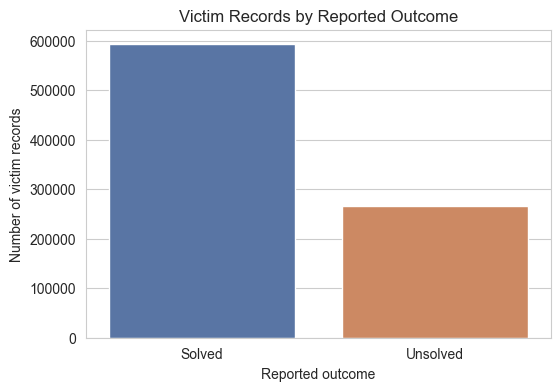

In [28]:
plt.figure(figsize=(6,4))
sns.countplot(x="outcome", data=df, order=["Solved", "Unsolved"],
              hue="outcome", palette=outcome_colors)
plt.title("Victim Records by Reported Outcome")
plt.xlabel("Reported outcome")
plt.ylabel("Number of victim records")
plt.show()


- After cleaning, there are 857,379 victim records and 815,358 distinct reported incident IDs.
- 265,109 records (30.9%) were reported unsolved.


### 5.2 Victim Age and Sex


In [29]:
df["victim_age"].describe()


count    844542.000000
mean         33.291604
std          16.213006
min           0.000000
25%          22.000000
50%          30.000000
75%          42.000000
max          99.000000
Name: victim_age, dtype: float64

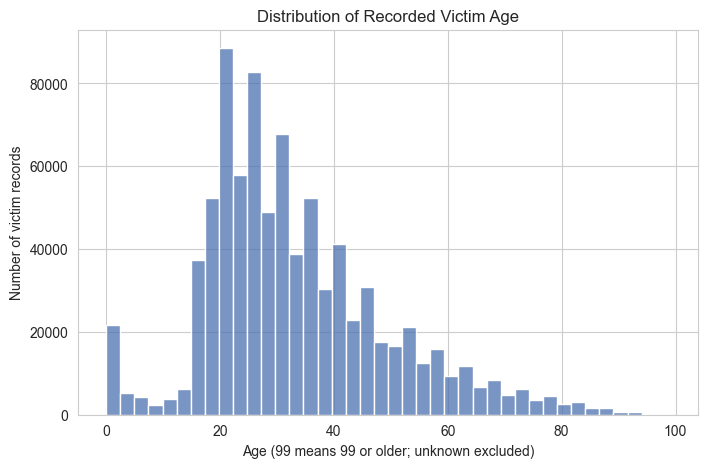

In [30]:
plt.figure(figsize=(8,5))
sns.histplot(x="victim_age", data=df, bins=40, color=solved_color)
plt.title("Distribution of Recorded Victim Age")
plt.xlabel("Age (99 means 99 or older; unknown excluded)")
plt.ylabel("Number of victim records")
plt.show()


Most victims are between about 18 and 40 years old, and the most common ages are in the early 20s. There is also a small peak at age 0 (babies under one year).

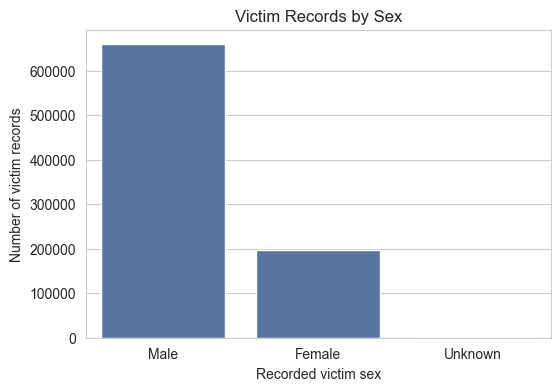

In [31]:
plt.figure(figsize=(6,4))
sns.countplot(x="victim_sex", data=df, order=["Male", "Female", "Unknown"], color=solved_color)
plt.title("Victim Records by Sex")
plt.xlabel("Recorded victim sex")
plt.ylabel("Number of victim records")
plt.show()


Most victim records are male (659,256), about three times more than female (196,413).

In [32]:
df.groupby("outcome")["victim_age"].describe()


,count,mean,std,min,25%,50%,75%,max
outcome,,,,,,,,
Solved,586239.0,33.457290,16.714918,0.0,22.0,30.0,43.0,99.0
Unsolved,258303.0,32.915568,15.004988,0.0,22.0,29.0,40.0,99.0


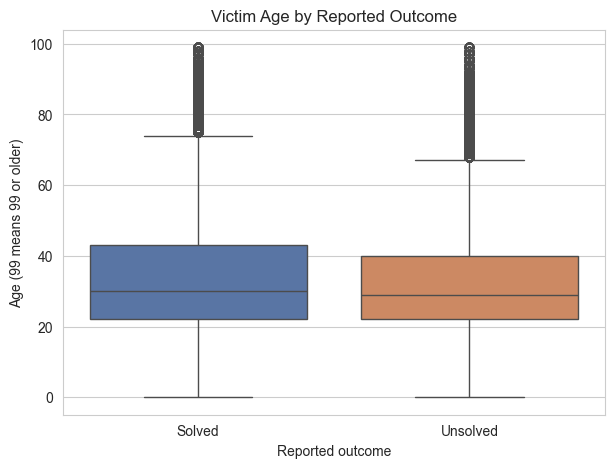

In [33]:
plt.figure(figsize=(7,5))
sns.boxplot(x="outcome", y="victim_age", data=df, order=["Solved", "Unsolved"],
            hue="outcome", palette=outcome_colors)
plt.title("Victim Age by Reported Outcome")
plt.xlabel("Reported outcome")
plt.ylabel("Age (99 means 99 or older)")
plt.show()


The median age is similar for solved and unsolved records. I kept valid ages outside the boxplot whiskers and will compare age groups next.


In [34]:
age_table = unsolved_table(df, "age_group").reindex(age_order)
age_table


,records,unsolved,unsolved %
age_group,,,
0-12,37148,4486,12.1
13-17,43676,13546,31.0
18-24,198760,68915,34.7
25-34,238051,78994,33.2
35-49,195051,56621,29.0
50-64,87365,23834,27.3
65+,44491,11907,26.8
Unknown,12837,6806,53.0


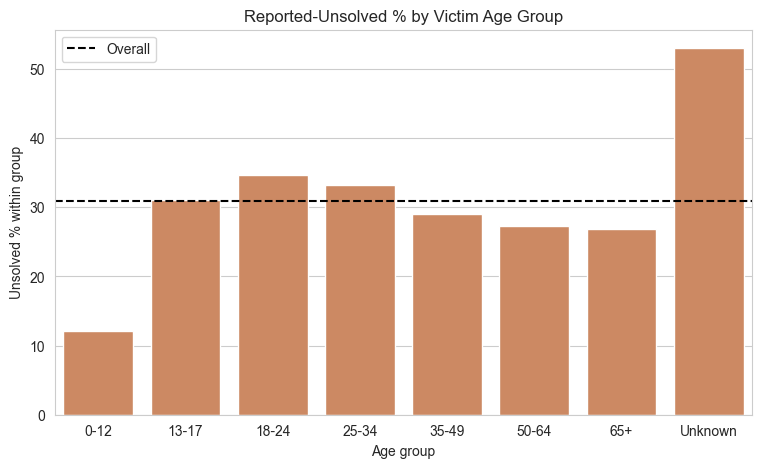

In [35]:
plt.figure(figsize=(9,5))
sns.barplot(x=age_table.index, y=age_table["unsolved %"], color=unsolved_color)
plt.axhline(baseline, color="black", linestyle="--", label="Overall")
plt.title("Reported-Unsolved % by Victim Age Group")
plt.xlabel("Age group")
plt.ylabel("Unsolved % within group")
plt.legend()
plt.show()


In [36]:
sex_table = unsolved_table(df, "victim_sex")
sex_table


,records,unsolved,unsolved %
victim_sex,,,
Unknown,1710,1002,58.6
Male,659256,219604,33.3
Female,196413,44503,22.7


In [37]:
race_table = unsolved_table(df, "victim_race")
race_table


,records,unsolved,unsolved %
victim_race,,,
Unknown,10776,4601,42.7
Black,414820,146625,35.3
Asian,12369,3603,29.1
White,412289,108729,26.4
American Indian or Alaskan Native,6845,1492,21.8
Native Hawaiian or Pacific Islander,280,59,21.1


- Ages 18-24 have the highest unsolved percentage among known age groups (34.7%). Ages 0-12 have the lowest (12.1%).
- Male records are 33.3% unsolved, compared with 22.7% for female records.
- Unknown age has a higher percentage (53.0%), but the age information is missing.


These race differences only describe the records. Place and time also differ between the groups, so they do not show an effect of race.


### 5.3 Crime Circumstances


In [38]:
circumstance_mix = pd.crosstab(df["circumstance_group"], df["outcome"], normalize="columns") * 100
circumstance_mix.round(1)


outcome,Solved,Unsolved
circumstance_group,,
Argument/Brawl,44.1,7.8
Drugs,3.6,4.3
Gang,2.9,6.1
Other,20.9,11.3
Other felony,2.7,2.4
Robbery,7.1,7.7
Suspected felony,0.7,3.7
Undetermined,18.0,56.6


Many unsolved records have undetermined circumstances. The known categories only describe part of the data.


In [39]:
specific_groups = ["Gang", "Drugs", "Robbery", "Other felony", "Argument/Brawl"]
specific = df[df["circumstance_group"].isin(specific_groups)]

circumstance_table = unsolved_table(df, "circumstance_group")
circumstance_table


,records,unsolved,unsolved %
circumstance_group,,,
Suspected felony,13881,9816,70.7
Undetermined,256660,149985,58.4
Gang,33197,16210,48.8
Drugs,32701,11459,35.0
Robbery,62668,20363,32.5
Other felony,22484,6464,28.7
Other,153902,30050,19.5
Argument/Brawl,281886,20762,7.4


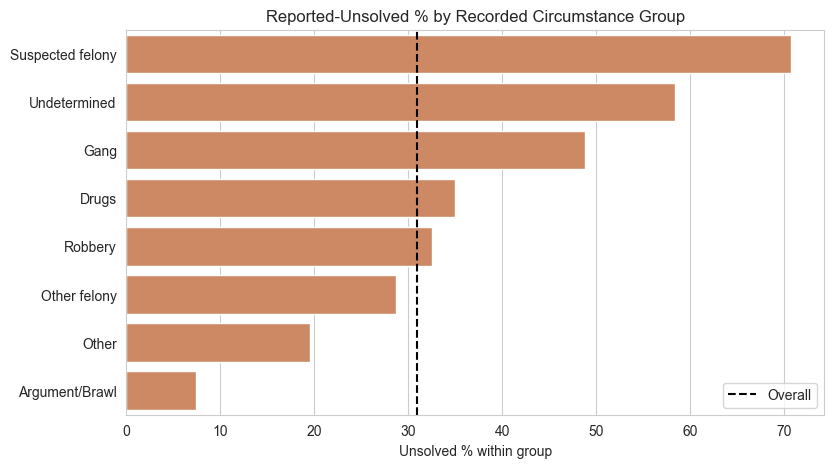

In [40]:
plt.figure(figsize=(9,5))
sns.barplot(x=circumstance_table["unsolved %"], y=circumstance_table.index, color=unsolved_color)
plt.axvline(baseline, color="black", linestyle="--", label="Overall")
plt.title("Reported-Unsolved % by Recorded Circumstance Group")
plt.xlabel("Unsolved % within group")
plt.ylabel("")
plt.legend()
plt.show()


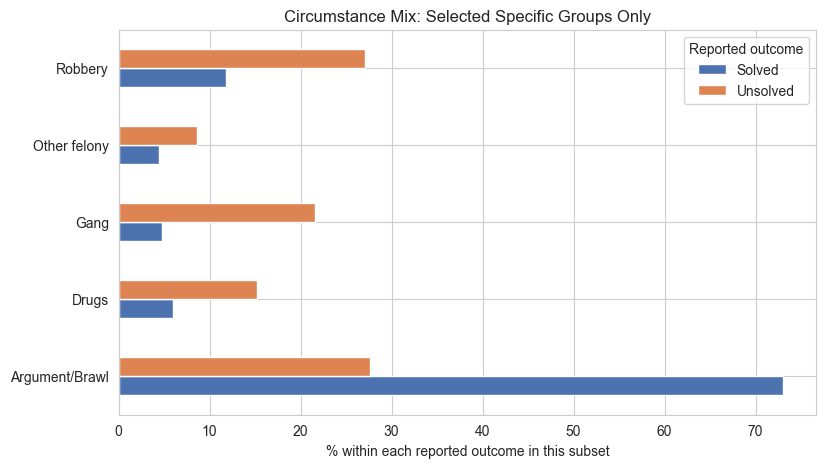

In [41]:
specific_mix = pd.crosstab(specific["circumstance_group"], specific["outcome"], normalize="columns") * 100
specific_mix.plot(kind="barh", figsize=(9,5), color=[solved_color, unsolved_color])
plt.title("Circumstance Mix: Selected Specific Groups Only")
plt.xlabel("% within each reported outcome in this subset")
plt.ylabel("")
plt.legend(title="Reported outcome")
plt.show()


In [42]:
circumstance_detail = unsolved_table(df, "circumstance")
circumstance_detail[circumstance_detail["records"] >= MIN_N]


,records,unsolved,unsolved %
circumstance,,,
All suspected felony type,13881,9816,70.7
Circumstances undetermined,256660,149985,58.4
Juvenile gang killings,26079,13120,50.3
Gangland killings,7118,3090,43.4
Arson,5220,1933,37.0
Narcotic drug laws,32701,11459,35.0
Other - not specified,31839,11090,34.8
Rape,4288,1398,32.6
Robbery,62668,20363,32.5


- Gang records are 48.8% unsolved, drugs 35.0%, robbery 32.5% and arguments/brawls 7.4%.
- However, 56.6% of all unsolved records have undetermined circumstances.


### 5.4 Weapons


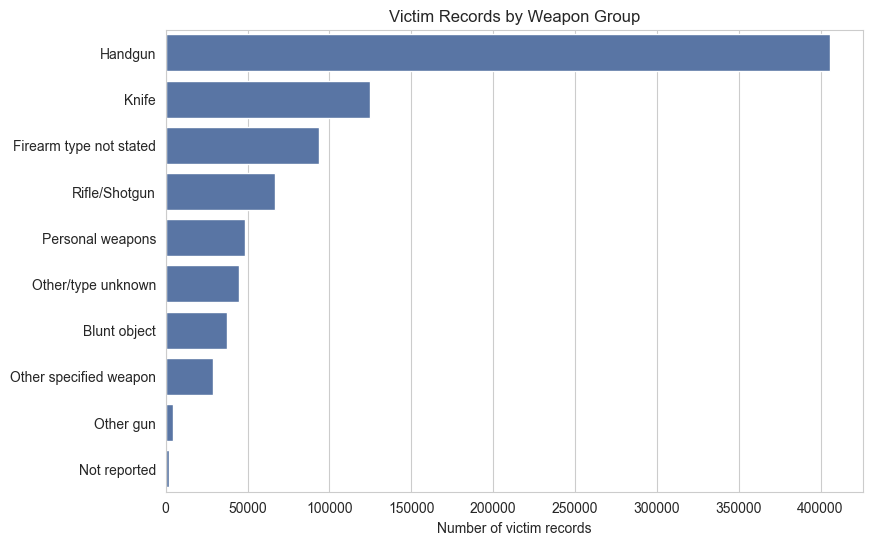

In [43]:
plt.figure(figsize=(9,6))
sns.countplot(y="weapon_group", data=df, order=df["weapon_group"].value_counts().index, color=solved_color)
plt.title("Victim Records by Weapon Group")
plt.xlabel("Number of victim records")
plt.ylabel("")
plt.show()


Handguns are the most common weapon by far (405,805 records), followed by knives (124,597).

In [44]:
weapon_table = unsolved_table(df, "weapon_group")
weapon_table["share of all unsolved %"] = (weapon_table["unsolved"] / df["unsolved"].sum() * 100).round(1)
weapon_table


,records,unsolved,unsolved %,share of all unsolved %
weapon_group,,,,
Not reported,1913,1374,71.8,0.5
Firearm type not stated,93763,43961,46.9,16.6
Other gun,4637,2089,45.1,0.8
Other/type unknown,45005,19133,42.5,7.2
Other specified weapon,28880,9479,32.8,3.6
Handgun,405805,132949,32.8,50.1
Blunt object,37139,11233,30.2,4.2
Knife,124597,25935,20.8,9.8
Personal weapons,48596,8271,17.0,3.1


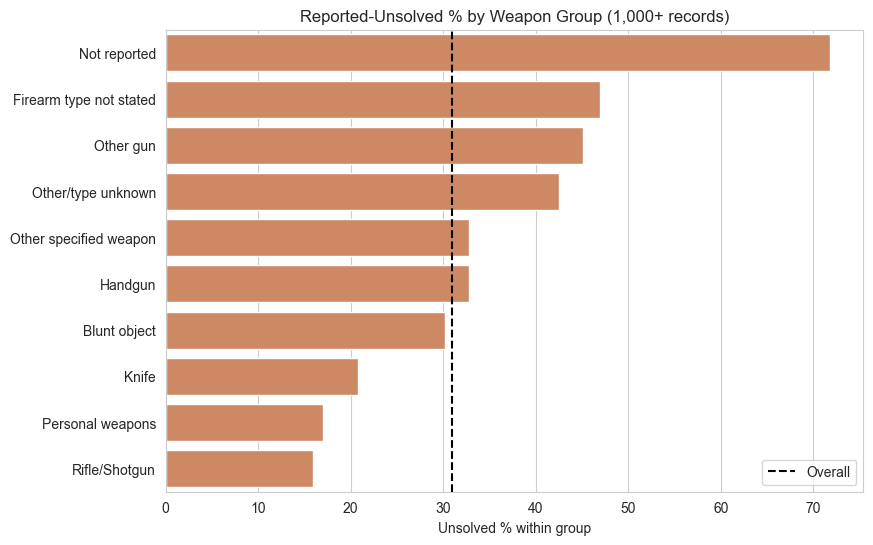

In [45]:
weapon_ranked = weapon_table[weapon_table["records"] >= MIN_N]
plt.figure(figsize=(9,6))
sns.barplot(x=weapon_ranked["unsolved %"], y=weapon_ranked.index, color=unsolved_color)
plt.axvline(baseline, color="black", linestyle="--", label="Overall")
plt.title("Reported-Unsolved % by Weapon Group (1,000+ records)")
plt.xlabel("Unsolved % within group")
plt.ylabel("")
plt.legend()
plt.show()


In [46]:
weapon_detail = unsolved_table(df, "weapon")
weapon_detail[weapon_detail["records"] >= MIN_N]


,records,unsolved,unsolved %
weapon,,,
Weapon Not Reported,1913,1374,71.8
"Firearm, type not stated",93763,43961,46.9
Strangulation - hanging,10124,4602,45.5
Other gun,4637,2089,45.1
Other or type unknown,45005,19133,42.5
Fire,7948,2625,33.0
"Handgun - pistol, revolver, etc",405805,132949,32.8
"Blunt object - hammer, club, etc",37139,11233,30.2
Asphyxiation - includes death by gas,5112,1228,24.0


- Handguns account for 50.1% of all unsolved records, while 32.8% of handgun records are unsolved.
- Rifle/shotgun records are 15.9% unsolved and knife records are 20.8%.
- Not reported weapons have a high percentage (71.8%) but only make up 0.5% of all unsolved records.


### 5.5 Relationship and Missing Details


In [47]:
relationship_mix = pd.crosstab(df["relationship_group"], df["outcome"], normalize="columns") * 100
relationship_mix.round(1)


outcome,Solved,Unsolved
relationship_group,,
Family,11.4,0.2
Not determined,17.9,93.2
Other known person,39.7,2.4
Partner/ex-partner,14.9,0.2
Stranger,16.2,3.9


In [48]:
relationship_recorded = df[df["relationship_group"] != "Not determined"]
(pd.crosstab(relationship_recorded["relationship_group"], relationship_recorded["outcome"],
             normalize="columns") * 100).round(1)


outcome,Solved,Unsolved
relationship_group,,
Family,13.8,3.0
Other known person,48.3,35.8
Partner/ex-partner,18.1,3.0
Stranger,19.7,58.2


The relationship is often unknown when no offender was identified. Comparisons with a known relationship only describe that subset.


In [49]:
missing_flags = pd.DataFrame({
    "Victim age unknown": df["victim_age"].isnull(),
    "Victim sex unknown": df["victim_sex"] == "Unknown",
    "Victim race unknown": df["victim_race"] == "Unknown",
    "Victim ethnicity unknown": df["victim_ethnicity"] == "Unknown or not reported",
    "Circumstance undetermined": df["circumstance"] == "Circumstances undetermined",
    "Relationship not determined": df["relationship_group"] == "Not determined",
    "Firearm type not stated": df["weapon_group"] == "Firearm type not stated",
    "Weapon not reported": df["weapon_group"] == "Not reported",
    "Offender sex unknown": df["offender_sex"] == "Unknown"
})
missing_by_outcome = (missing_flags.groupby(df["outcome"]).mean().T * 100).round(1)
missing_by_outcome


outcome,Solved,Unsolved
Victim age unknown,1.0,2.6
Victim sex unknown,0.1,0.4
Victim race unknown,1.0,1.7
Victim ethnicity unknown,56.3,55.7
Circumstance undetermined,18.0,56.6
Relationship not determined,17.9,93.2
Firearm type not stated,8.4,16.6
Weapon not reported,0.1,0.5
Offender sex unknown,0.0,99.8


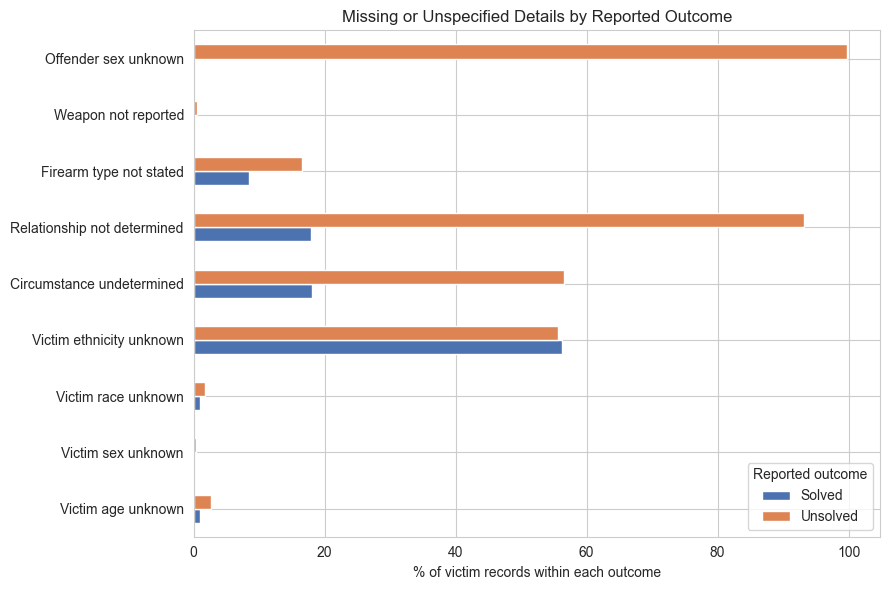

In [50]:
missing_by_outcome.plot(kind="barh", figsize=(9,6), color=[solved_color, unsolved_color])
plt.title("Missing or Unspecified Details by Reported Outcome")
plt.xlabel("% of victim records within each outcome")
plt.ylabel("")
plt.legend(title="Reported outcome")
plt.tight_layout()
plt.show()


Unsolved records have many more missing details. The relationship is not determined in 93.2% of unsolved records, compared with 17.9% of solved records. Ethnicity is unknown in about 56% of both groups, so that is a general reporting problem.

### 5.6 Place and Reporting Coverage


In [51]:
coverage = df.groupby("state").agg(records=("unsolved", "size"),
                                    years_with_data=("year", "nunique"),
                                    agencies=("agency_code", "nunique"))
map_share = (df["source"] == "MAP").groupby(df["state"]).mean() * 100
coverage["MAP source %"] = map_share.round(1)
coverage.sort_values("years_with_data").head(10)


,records,years_with_data,agencies,MAP source %
state,,,,
District of Columbia,9729,43,7,13.6
Kansas,4611,43,222,0.0
Montana,1059,45,93,0.0
Florida,48231,46,415,56.9
Maine,1179,47,131,0.0
Kentucky,10520,48,358,0.0
Iowa,2648,48,205,0.0
New Hampshire,879,48,131,0.0
Wisconsin,8805,48,290,0.0


In [52]:
state_table = unsolved_table(df, "state")
state_ranked = state_table[state_table["records"] >= MIN_N]
print("States/DC excluded from ranking:")
print(state_table[state_table["records"] < MIN_N])
state_ranked.head(10)


States/DC excluded from ranking:
               records  unsolved  unsolved %
state                                       
New Hampshire      879       130        14.8
Vermont            561        70        12.5
Wyoming            820        91        11.1
South Dakota       733        61         8.3
North Dakota       530        31         5.8


,records,unsolved,unsolved %
state,,,
District of Columbia,9729,5945,61.1
New York,61388,27003,44.0
Maryland,23093,9919,43.0
Illinois,37905,15904,42.0
California,122816,48697,39.7
New Jersey,18197,6737,37.0
Missouri,21515,7921,36.8
Massachusetts,8134,2900,35.7
Indiana,16061,5573,34.7


Among groups with at least 1,000 records, D.C. has the highest unsolved percentage (61.1%), followed by New York (44.0%) and Maryland (43.0%).


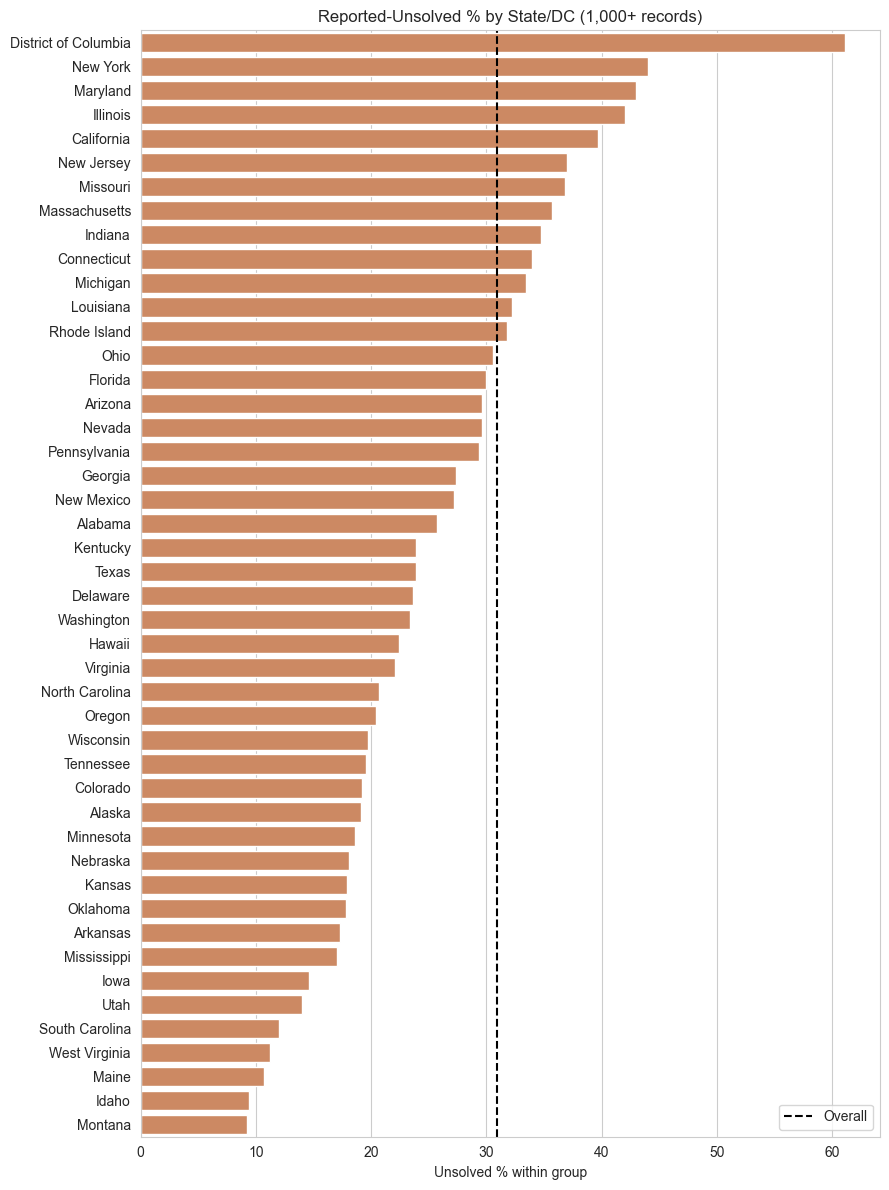

In [53]:
plt.figure(figsize=(9,12))
sns.barplot(x=state_ranked["unsolved %"], y=state_ranked.index, color=unsolved_color)
plt.axvline(baseline, color="black", linestyle="--", label="Overall")
plt.title("Reported-Unsolved % by State/DC (1,000+ records)")
plt.xlabel("Unsolved % within group")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()


Not all agencies report every year, so states are not fully comparable. D.C. is a district, not a state.


In [54]:
msa_table = unsolved_table(df, "msa")
msa_ranked = msa_table[msa_table["records"] >= MIN_N]
msa_ranked.head(10)


,records,unsolved,unsolved %
msa,,,
"Buffalo-Niagara Falls, NY",2884,1433,49.7
"Salinas, CA",1421,688,48.4
"Washington-Arlington-Alexandria, DC-VA-MD-WV",18232,8691,47.7
"Baltimore-Towson, MD",15783,7383,46.8
"San Francisco-Oakland-Fremont, CA",15432,7199,46.6
"St. Louis, MO-IL",12734,5915,46.5
"New York-New Jersey-Long Island, NY-NJ",63569,28499,44.8
"Chicago-Naperville-Joliet, IL-IN-WI",37283,16634,44.6
"New Orleans-Metairie-Kenner, LA",12596,5608,44.5


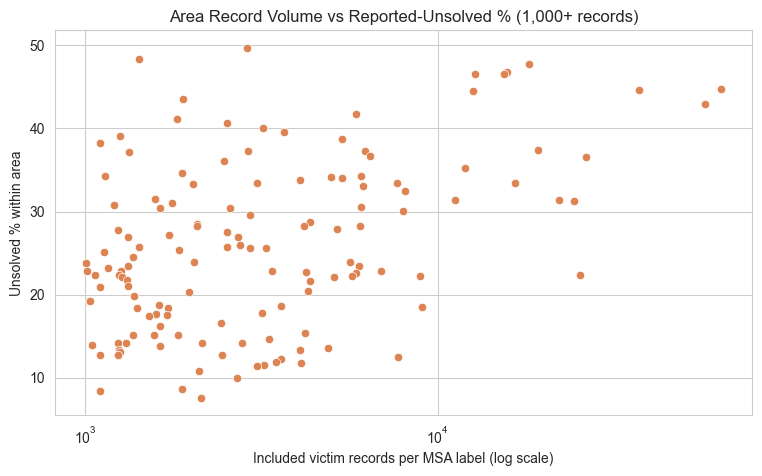

In [55]:
plt.figure(figsize=(9,5))
sns.scatterplot(x="records", y="unsolved %", data=msa_ranked, color=unsolved_color)
plt.xscale("log")
plt.title("Area Record Volume vs Reported-Unsolved % (1,000+ records)")
plt.xlabel("Included victim records per MSA label (log scale)")
plt.ylabel("Unsolved % within area")
plt.show()


In [56]:
msa_ranked[["records", "unsolved %"]].corr(method="spearman")


,records,unsolved %
records,1.000000,0.369669
unsolved %,0.369669,1.000000


The Spearman correlation is about 0.37. Areas with more records tend to have higher unsolved percentages, but there are many exceptions.


Record count is not population size. Some MSA labels are rural groups rather than individual cities.


### 5.7 Time


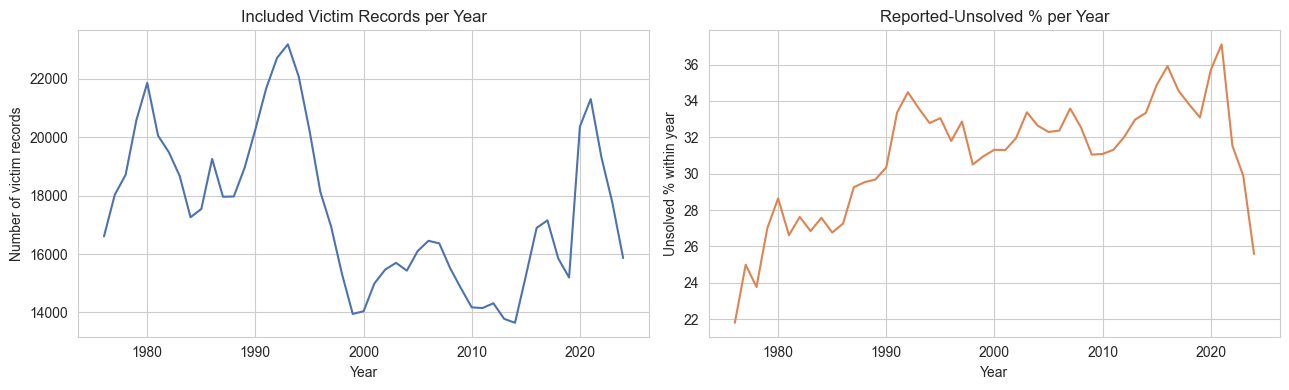

In [57]:
year_table = df.groupby("year")["unsolved"].agg(records="size", unsolved_pct="mean")
year_table["unsolved_pct"] = year_table["unsolved_pct"] * 100

fig, axes = plt.subplots(1, 2, figsize=(13,4))
axes[0].plot(year_table.index, year_table["records"], color=solved_color)
axes[0].set_title("Included Victim Records per Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of victim records")
axes[1].plot(year_table.index, year_table["unsolved_pct"], color=unsolved_color)
axes[1].set_title("Reported-Unsolved % per Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Unsolved % within year")
plt.tight_layout()
plt.show()


In [58]:
year_table.loc[[1976, 1992, 2014, 2021, 2024]].round(1)


,records,unsolved_pct
year,,
1976,16605,21.8
1992,22716,34.5
2014,13646,33.3
2021,21307,37.1
2024,15862,25.6


The unsolved percentage is 21.8% in 1976, 37.1% in 2021 and 25.6% in 2024. Reporting differences and updates may affect the recent decline.


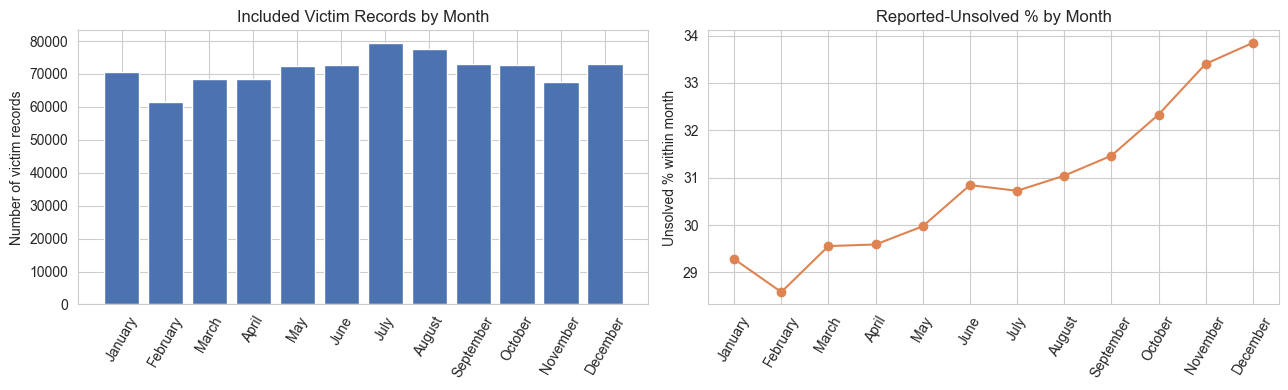

In [59]:
month_table = df.groupby("month", observed=True)["unsolved"].agg(records="size", unsolved_pct="mean")
month_table["unsolved_pct"] = month_table["unsolved_pct"] * 100

fig, axes = plt.subplots(1, 2, figsize=(13,4))
axes[0].bar(month_table.index.astype(str), month_table["records"], color=solved_color)
axes[0].set_title("Included Victim Records by Month")
axes[0].set_ylabel("Number of victim records")
axes[0].tick_params(axis="x", rotation=60)
axes[1].plot(month_table.index.astype(str), month_table["unsolved_pct"], marker="o", color=unsolved_color)
axes[1].set_title("Reported-Unsolved % by Month")
axes[1].set_ylabel("Unsolved % within month")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()


Annual counts also depend on reporting coverage. Months have different lengths, and dates can refer to body recovery. These charts do not show how long solving a case took.


In [60]:
missing_by_period = missing_flags.groupby(df["period"], observed=True).mean() * 100
missing_by_period[["Circumstance undetermined", "Firearm type not stated"]].round(1)


,Circumstance undetermined,Firearm type not stated
period,,
1976-79,13.8,3.4
1980s,21.4,4.1
1990s,29.6,5.6
2000s,32.8,10.4
2010s,35.7,19.3
2020-24,46.5,29.1


Undetermined circumstances increased from 13.8% in 1976-79 to 46.5% in 2020-24. Missing firearm type also became more common, which limits comparisons over time.


### 5.8 Combined Patterns


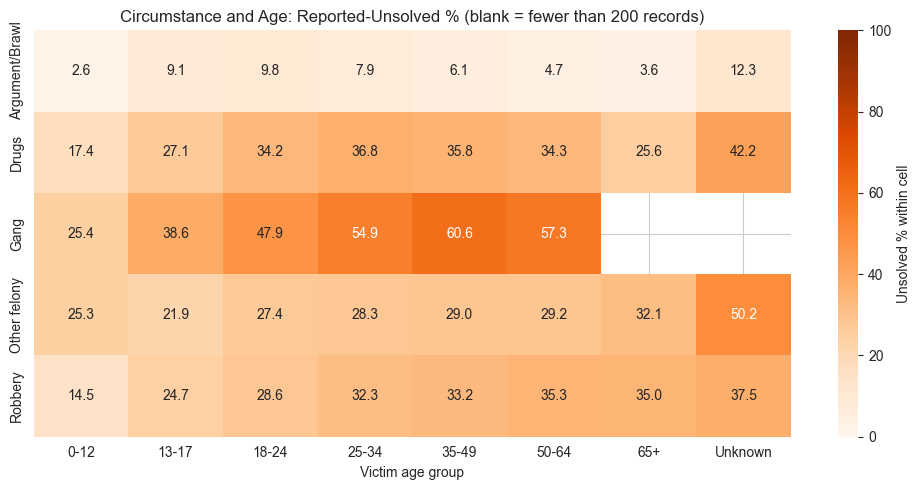

In [61]:
heat_pct = specific.pivot_table(index="circumstance_group", columns="age_group",
                                values="unsolved", aggfunc="mean", observed=True) * 100
heat_n = specific.pivot_table(index="circumstance_group", columns="age_group",
                              values="unsolved", aggfunc="size", observed=True)
heat_pct = heat_pct.reindex(columns=age_order).where(heat_n.reindex(columns=age_order) >= MIN_CELL)

plt.figure(figsize=(10,5))
sns.heatmap(heat_pct, annot=True, fmt=".1f", cmap="Oranges", vmin=0, vmax=100,
            cbar_kws={"label": "Unsolved % within cell"})
plt.title("Circumstance and Age: Reported-Unsolved % (blank = fewer than 200 records)")
plt.xlabel("Victim age group")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [62]:
heat_n.reindex(columns=age_order)


age_group,0-12,13-17,18-24,25-34,35-49,50-64,65+,Unknown
circumstance_group,,,,,,,,
Argument/Brawl,3127,10885,63729,86888,75244,29776,10027,2210
Drugs,201,1534,10752,11970,6591,1163,234,256
Gang,335,6383,14911,7713,3052,599,102,102
Other felony,1954,1199,3552,4505,4221,3023,3711,319
Robbery,221,1815,11374,14341,14923,10971,8487,536


For ages 35-49, gang records are 60.6% unsolved, compared with 6.1% for arguments/brawls. The table shows the number of records in each cell.


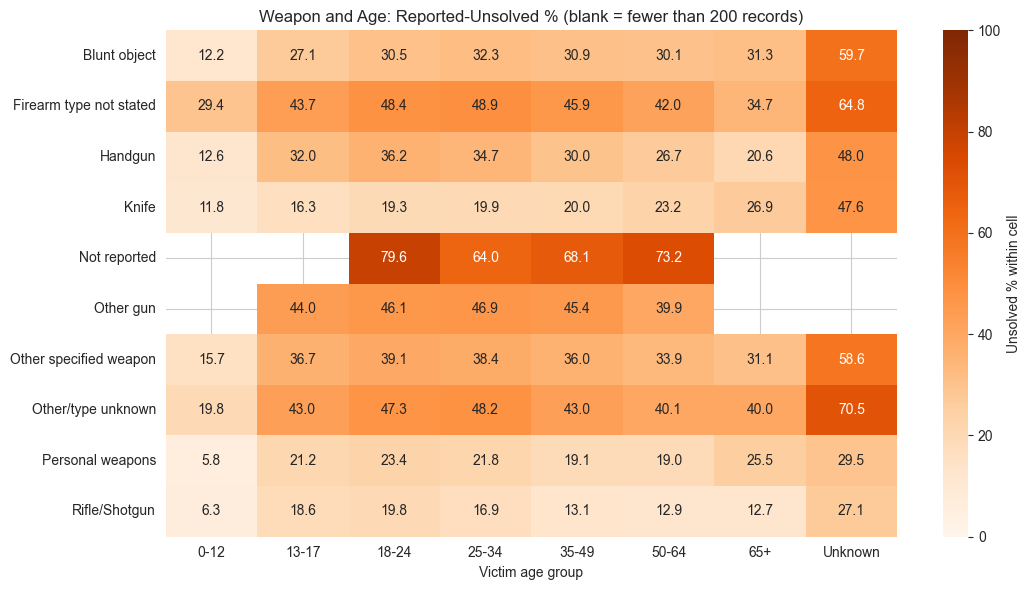

In [63]:
weapon_age_pct = df.pivot_table(index="weapon_group", columns="age_group",
                                values="unsolved", aggfunc="mean", observed=True) * 100
weapon_age_n = df.pivot_table(index="weapon_group", columns="age_group",
                              values="unsolved", aggfunc="size", observed=True)
weapon_age_pct = weapon_age_pct.reindex(columns=age_order).where(weapon_age_n.reindex(columns=age_order) >= MIN_CELL)

plt.figure(figsize=(11,6))
sns.heatmap(weapon_age_pct, annot=True, fmt=".1f", cmap="Oranges", vmin=0, vmax=100,
            cbar_kws={"label": "Unsolved % within cell"})
plt.title("Weapon and Age: Reported-Unsolved % (blank = fewer than 200 records)")
plt.xlabel("Victim age group")
plt.ylabel("")
plt.tight_layout()
plt.show()


Rifle/shotgun and personal weapons stay low in every known age group (under 26%). When the victim's age is unknown, the unsolved percentage is higher for every weapon with enough records.

#### Frequent Profiles vs High Unsolved Percentages


In [64]:
profile_cols = ["circumstance_group", "weapon_group", "victim_sex", "age_group"]
profiles = df.groupby(profile_cols, observed=True)["unsolved"].agg(records="size", unsolved="sum")
profiles["unsolved %"] = (profiles["unsolved"] / profiles["records"] * 100).round(1)
profiles["share of all unsolved %"] = (profiles["unsolved"] / df["unsolved"].sum() * 100).round(1)
profiles.sort_values("unsolved", ascending=False).head(10)


records  \
circumstance_group weapon_group            victim_sex age_group            
Undetermined       Handgun                 Male       25-34        34052   
                                                      18-24        30827   
                                                      35-49        20716   
                   Firearm type not stated Male       25-34        13236   
                                                      18-24        12204   
                                                      35-49         9258   
Gang               Handgun                 Male       18-24        10954   
Argument/Brawl     Handgun                 Male       25-34        35982   
Undetermined       Handgun                 Male       50-64         6412   
Argument/Brawl     Handgun                 Male       18-24        29326   

                                                                 unsolved  \
circumstance_group weapon_group            victim_sex age_group             
Undetermined       Handgun                 Male       25-34         22205   
                                                      18-24         19325   
                                                      35-49         13071   
                   Firearm type not stated Male       25-34          8409   
                                                      18-24          7385   
                                                      35-49          5721   
Gang               Handgun                 Male       18-24          5465   
Argument/Brawl     Handgun                 Male       25-34          3862   
Undetermined       Handgun                 Male       50-64          3849   
Argument/Brawl     Handgun                 Male       18-24          3753   

                                                                 unsolved %  \
circumstance_group weapon_group            victim_sex age_group               
Undetermined       Handgun                 Male       25-34            65.2   
                                                      18-24            62.7   
                                                      35-49            63.1   
                   Firearm type not stated Male       25-34            63.5   
                                                      18-24            60.5   
                                                      35-49            61.8   
Gang               Handgun                 Male       18-24            49.9   
Argument/Brawl     Handgun                 Male       25-34            10.7   
Undetermined       Handgun                 Male       50-64            60.0   
Argument/Brawl     Handgun                 Male       18-24            12.8   

                                                                 share of all unsolved %  
circumstance_group weapon_group            victim_sex age_group                           
Undetermined       Handgun                 Male       25-34                          8.4  
                                                      18-24                          7.3  
                                                      35-49                          4.9  
                   Firearm type not stated Male       25-34                          3.2  
                                                      18-24                          2.8  
                                                      35-49                          2.2  
Gang               Handgun                 Male       18-24                          2.1  
Argument/Brawl     Handgun                 Male       25-34                          1.5  
Undetermined       Handgun                 Male       50-64                          1.5  
Argument/Brawl     Handgun                 Male       18-24                          1.4

In [65]:
specific_profiles = profiles.loc[profiles.index.get_level_values("circumstance_group").isin(specific_groups)]
specific_profiles.sort_values("unsolved", ascending=False).head(10)


records  unsolved  \
circumstance_group weapon_group victim_sex age_group                      
Gang               Handgun      Male       18-24        10954      5465   
Argument/Brawl     Handgun      Male       25-34        35982      3862   
                                           18-24        29326      3753   
Gang               Handgun      Male       25-34         5617      3189   
Drugs              Handgun      Male       25-34         7717      3053   
Robbery            Handgun      Male       25-34         8791      2875   
                                           35-49         8163      2826   
Drugs              Handgun      Male       18-24         7259      2688   
Robbery            Handgun      Male       18-24         7325      2169   
Argument/Brawl     Handgun      Male       35-49        25485      2060   

                                                      unsolved %  \
circumstance_group weapon_group victim_sex age_group               
Gang               Handgun      Male       18-24            49.9   
Argument/Brawl     Handgun      Male       25-34            10.7   
                                           18-24            12.8   
Gang               Handgun      Male       25-34            56.8   
Drugs              Handgun      Male       25-34            39.6   
Robbery            Handgun      Male       25-34            32.7   
                                           35-49            34.6   
Drugs              Handgun      Male       18-24            37.0   
Robbery            Handgun      Male       18-24            29.6   
Argument/Brawl     Handgun      Male       35-49             8.1   

                                                      share of all unsolved %  
circumstance_group weapon_group victim_sex age_group                           
Gang               Handgun      Male       18-24                          2.1  
Argument/Brawl     Handgun      Male       25-34                          1.5  
                                           18-24                          1.4  
Gang               Handgun      Male       25-34                          1.2  
Drugs              Handgun      Male       25-34                          1.2  
Robbery            Handgun      Male       25-34                          1.1  
                                           35-49                          1.1  
Drugs              Handgun      Male       18-24                          1.0  
Robbery            Handgun      Male       18-24                          0.8  
Argument/Brawl     Handgun      Male       35-49                          0.8

Among the selected circumstance groups, gang + handgun + male + age 18-24 has the most unsolved records (5,465). This profile has 10,954 records in total, with 49.9% reported unsolved.


The first table includes undetermined circumstances. The second only uses selected specific groups. A common unsolved profile does not always have the highest unsolved percentage.


#### Compare Within the Same State and Period


I will compare gang and argument/brawl records within the same state and period. Both groups need at least 200 records.


In [66]:
comparison = df[df["circumstance_group"].isin(["Gang", "Argument/Brawl"])]
within_pct = comparison.pivot_table(index=["state", "period"], columns="circumstance_group",
                                    values="unsolved", aggfunc="mean", observed=True) * 100
within_n = comparison.pivot_table(index=["state", "period"], columns="circumstance_group",
                                  values="unsolved", aggfunc="size", observed=True)
keep = (within_n["Gang"] >= MIN_CELL) & (within_n["Argument/Brawl"] >= MIN_CELL)
within_pct = within_pct[keep].copy()
within_pct["difference (percentage points)"] = within_pct["Gang"] - within_pct["Argument/Brawl"]
within_pct.round(1).head(10)


circumstance_group  Argument/Brawl  Gang  difference (percentage points)
state      period                                                       
California 1976-79             8.0  40.1                            32.1
           1980s              11.2  40.3                            29.1
           1990s              14.1  45.8                            31.7
           2000s              14.1  53.2                            39.2
           2010s              10.3  64.8                            54.5
           2020-24            29.2  72.0                            42.8
Illinois   1980s               2.6  18.3                            15.7
           1990s               6.2  19.0                            12.9
           2000s              27.2  61.6                            34.4
           2010s              35.4  82.2                            46.7

In [67]:
print("State-periods compared:", len(within_pct))
print("Gang higher:", (within_pct["difference (percentage points)"] > 0).sum())
print("Median difference:", round(within_pct["difference (percentage points)"].median(), 1))


State-periods compared: 14
Gang higher: 14
Median difference: 31.9


Gang records have a higher unsolved percentage in all 14 state-periods with enough records. So the difference is not only because gang and argument cases come from different states or years.


#### Check the Effect of Multiple-Victim Records


In [68]:
single_victim = df[df["additional_victims"] == 0]
single_circumstance = unsolved_table(single_victim, "circumstance_group")

sensitivity = pd.DataFrame({"All victim records: unsolved %": circumstance_table["unsolved %"],
                            "Single-victim reports: unsolved %": single_circumstance["unsolved %"]})
sensitivity


,All victim records: unsolved %,Single-victim reports: unsolved %
circumstance_group,,
Suspected felony,70.7,71.4
Undetermined,58.4,59.1
Gang,48.8,48.7
Drugs,35.0,34.9
Robbery,32.5,33.1
Other felony,28.7,28.4
Other,19.5,20.2
Argument/Brawl,7.4,7.4


Single-victim reports show similar circumstance percentages. This suggests that the pattern is not mainly from counting multiple victims in the same incident.


### 5.9 Numeric Correlation


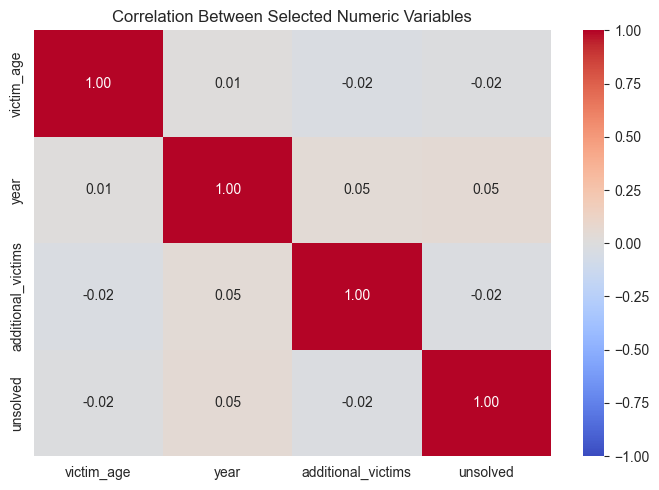

In [69]:
numeric_cols = ["victim_age", "year", "additional_victims", "unsolved"]
corr = df[numeric_cols].corr()

plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Selected Numeric Variables")
plt.tight_layout()
plt.show()


The numeric correlations are weak. Most columns in this dataset are categories, so the group comparisons above are more useful. I did not use offender details here because they are usually only known when the case is solved.


## 6. Save the Cleaned Data
I will save the cleaned data with the new columns for the Streamlit dashboard.


In [70]:
df.to_csv("clean_data_shr.csv", index=False)
print("Saved: clean_data_shr.csv")
print("Rows:", len(df))
print("Columns:", df.shape[1])


Saved: clean_data_shr.csv
Rows: 857379
Columns: 38


## 7. Main Insights

- There are 857,379 victim records after cleaning. About 31% were reported unsolved.
- Gang records have a higher unsolved percentage (48.8%) than arguments/brawls (7.4%).
- Handguns make up about half of all unsolved records.
- Ages 18-24 have the highest percentage among known age groups (34.7%).
- Male records have a higher overall percentage than female records (33.3% vs 22.7%).
- Circumstance is undetermined in 56.6% of unsolved records. Relationship is not determined in 93.2%.
- The gang/argument difference also appears in the eligible state-period comparisons and single-victim reports.

These are patterns in the recorded data. They do not prove why individual cases were unsolved.


## 8. Limitations

- Solved means an offender was identified when the report was made. It is not current case status.
- Each row is a victim, so one incident may have several rows.
- Reporting coverage differs across places and years.
- Many unsolved records have missing circumstances and relationships.
- Some repeated records and broad categories may affect the results.
- The analysis shows associations, not causes.


## 9. What I Learned

- A big real dataset needs careful checking before cleaning. Codes like 999 and labels like "Unknown" are missing values, even when `isnull()` shows nothing.
- The unsolved % inside a group and the share of all unsolved records are different things. Handguns are half of all unsolved records, but their unsolved % is close to the average.
- Small groups can give misleading percentages, so I only ranked groups with enough records.
- Missing information is also a pattern. Many details are only known after an offender is found.
- How to turn the analysis into an interactive Streamlit dashboard with filters.

## 10. Recommendations for Future Analysis

- Add population data to calculate rates per 100,000 people instead of record counts.
- Get the current case status, because "solved" here only means solved when the report was made.
- Build a simple model, for example logistic regression, to see which factors together predict an unsolved case.
- Compare places over time using only agencies that reported every year.
- Analyse incidents instead of victims, so cases with many victims are counted once.